# A/B Test Analysis: Does Moving the First Gate Hurt Player Retention?

**Author:** Odesha Hill

## Business question
Cookie Cats is a mobile puzzle game. At certain levels, players hit a "gate" where they must wait or make an in-app purchase to continue. The team tested moving the first gate from **level 30 (control)** to **level 40 (treatment)**.

**Decision to support:** Should the game move the first gate to level 40?

## Experiment design
- **Unit of randomization:** player, assigned at install
- **Groups:** `gate_30` (control) and `gate_40` (treatment)
- **Primary metric:** 7-day retention (did the player return 7 days after install?)
- **Secondary metrics:** 1-day retention, total game rounds in the first 14 days
- **Significance level:** α = 0.05, two-sided tests

**Hypotheses (for each retention metric):**
- H₀: retention is the same in both groups
- H₁: retention differs between groups

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.power import NormalIndPower

np.random.seed(42)
df = pd.read_csv("data/cookie_cats.csv")
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Data quality checks
Before testing anything, confirm the data is clean: one row per player, no missing values, and no extreme values that could distort results.

In [2]:
print("Rows:", len(df))
print("Duplicate players:", df["userid"].duplicated().sum())
print("Missing values:", df.isna().sum().sum())
df["sum_gamerounds"].describe()

Rows: 90189
Duplicate players: 0
Missing values: 0


count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

One player logged 49,854 game rounds in 14 days, about 17 times the next highest player. That's almost certainly a logging error or a bot, so I exclude this player from the **game rounds** analysis only. It doesn't affect the retention metrics, which are yes/no values.

In [3]:
print(df.nlargest(3, "sum_gamerounds"))
rounds = df[df["sum_gamerounds"] < df["sum_gamerounds"].max()]

        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False


## 2. Experiment health check: sample ratio mismatch (SRM)
If players were split 50/50, the two groups should be nearly equal in size. A chi-square test checks whether the observed split could plausibly come from a 50/50 assignment. A significant result means the randomization or logging may be broken, and results need extra caution.

In [4]:
counts = df["version"].value_counts()
print(counts)
chi2, p_srm = stats.chisquare(counts.values)
print(f"\nSRM chi-square p-value: {p_srm:.4f}")

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

SRM chi-square p-value: 0.0086


**Finding:** the groups differ by 789 players (44,700 vs. 45,489), and the SRM test is significant (p ≈ 0.009). If the intended split was 50/50, something in assignment or logging is uneven.

The dataset doesn't include install dates or platform, so I can't diagnose the cause. In a real setting, I'd stop and investigate before trusting the results. Here, I proceed with the analysis and flag the SRM as a key limitation in the recommendation.

## 3. Retention by group

In [5]:
summary = df.groupby("version").agg(
    players=("userid", "count"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
)
summary[["retention_1", "retention_7"]] = (summary[["retention_1", "retention_7"]] * 100).round(2)
summary

,players,retention_1,retention_7
version,,,
gate_30,44700,44.82,19.02
gate_40,45489,44.23,18.20


## 4. Hypothesis tests: two-proportion z-tests
For each retention metric, I test whether the difference between groups is statistically significant and calculate a 95% confidence interval for the difference (gate_40 minus gate_30).

In [6]:
def test_retention(metric):
    s = df.groupby("version")[metric].sum()
    n = df.groupby("version")[metric].count()
    z, p = proportions_ztest([s["gate_40"], s["gate_30"]], [n["gate_40"], n["gate_30"]])
    lo, hi = confint_proportions_2indep(s["gate_40"], n["gate_40"], s["gate_30"], n["gate_30"])
    diff = s["gate_40"] / n["gate_40"] - s["gate_30"] / n["gate_30"]
    return {"metric": metric, "difference_pp": round(diff * 100, 2),
            "ci_low_pp": round(lo * 100, 2), "ci_high_pp": round(hi * 100, 2),
            "z": round(z, 2), "p_value": round(p, 4)}

results = pd.DataFrame([test_retention("retention_1"), test_retention("retention_7")])
results

,metric,difference_pp,ci_low_pp,ci_high_pp,z,p_value
0,retention_1,-0.59,-1.24,0.06,-1.78,0.0744
1,retention_7,-0.82,-1.33,-0.31,-3.16,0.0016


**Results:**
- **1-day retention:** gate_40 is 0.59 percentage points lower, but the difference is **not statistically significant** (p ≈ 0.07). The confidence interval includes zero.
- **7-day retention:** gate_40 is 0.82 percentage points lower, and the difference **is statistically significant** (p ≈ 0.002). The 95% confidence interval runs from about −1.33 to −0.31 percentage points, entirely below zero.

## 5. Bootstrap check
As a second, assumption-light check, I resample players with replacement 1,000 times and look at the distribution of the retention difference. If most of the distribution sits below zero, the drop is robust.

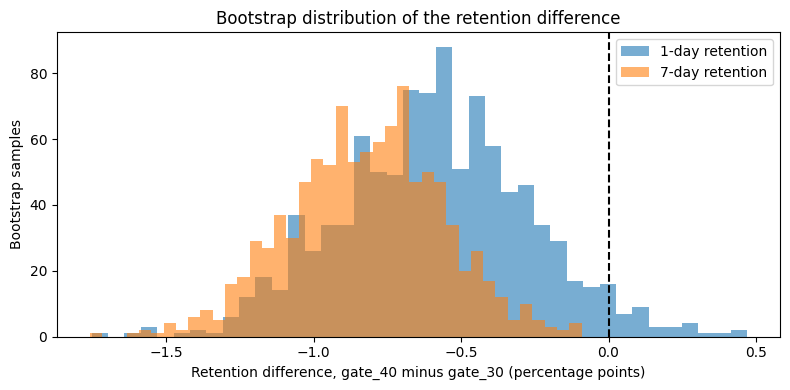

retention_1: share of bootstrap samples where gate_40 is lower = 96.5%
retention_7: share of bootstrap samples where gate_40 is lower = 100.0%


In [7]:
boot = []
for _ in range(1000):
    sample = df.sample(frac=1, replace=True)
    r = sample.groupby("version")[["retention_1", "retention_7"]].mean()
    boot.append((r.loc["gate_40"] - r.loc["gate_30"]) * 100)
boot = pd.DataFrame(boot)

fig, ax = plt.subplots(figsize=(8, 4))
for col, label in [("retention_1", "1-day retention"), ("retention_7", "7-day retention")]:
    ax.hist(boot[col], bins=40, alpha=0.6, label=label)
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Retention difference, gate_40 minus gate_30 (percentage points)")
ax.set_ylabel("Bootstrap samples")
ax.set_title("Bootstrap distribution of the retention difference")
ax.legend()
plt.tight_layout()
plt.show()

for col in ["retention_1", "retention_7"]:
    print(f"{col}: share of bootstrap samples where gate_40 is lower = {(boot[col] < 0).mean():.1%}")

## 6. Was the test sensitive enough? Minimum detectable effect
A power analysis shows the smallest 7-day retention drop this sample size could reliably detect (80% power, α = 0.05). This helps judge whether a non-significant result means "no effect" or "too small to detect."

In [8]:
n30 = (df["version"] == "gate_30").sum()
n40 = (df["version"] == "gate_40").sum()
p0 = df.loc[df["version"] == "gate_30", "retention_7"].mean()
h = NormalIndPower().solve_power(nobs1=n30, alpha=0.05, power=0.8, ratio=n40 / n30)
p1 = np.sin(np.arcsin(np.sqrt(p0)) - h / 2) ** 2
print(f"Baseline 7-day retention: {p0:.2%}")
print(f"Minimum detectable drop at 80% power: {(p0 - p1) * 100:.2f} percentage points")

Baseline 7-day retention: 19.02%
Minimum detectable drop at 80% power: 0.73 percentage points


The test could reliably detect a 7-day retention change of about 0.73 percentage points. The observed drop (0.82 points) is just above that threshold, which is consistent with it being statistically significant. For 1-day retention, a real effect smaller than about this size could have gone undetected.

## 7. Secondary metric: engagement (game rounds)
Game rounds are heavily skewed (most players play few rounds, a few play thousands), so I use the Mann-Whitney U test instead of a t-test, with the outlier removed.

In [9]:
g30 = rounds.loc[rounds["version"] == "gate_30", "sum_gamerounds"]
g40 = rounds.loc[rounds["version"] == "gate_40", "sum_gamerounds"]
print(f"Median rounds: gate_30 = {g30.median():.0f}, gate_40 = {g40.median():.0f}")
u, p_mw = stats.mannwhitneyu(g30, g40)
print(f"Mann-Whitney p-value: {p_mw:.4f}")

Median rounds: gate_30 = 17, gate_40 = 16
Mann-Whitney p-value: 0.0509


Median game rounds are nearly identical (17 vs. 16), and the difference is not statistically significant (p ≈ 0.051, just above the 0.05 threshold). Moving the gate didn't meaningfully change how much people played in the first two weeks, so the retention drop is the main finding.

## 8. Recommendation
**Keep the first gate at level 30.**

- Moving the gate to level 40 **lowered 7-day retention by about 0.8 percentage points** (from 19.0% to 18.2%), a statistically significant drop confirmed by the bootstrap check. That's roughly a 4% relative decline in players still active after a week.
- 1-day retention also trended lower, though not significantly.
- There's no evidence the change improved anything.

One plausible explanation: an earlier gate gives players a natural break, which may keep the game feeling fresh and bring them back. That's a hypothesis for future testing, not something this data proves.

**Limitations:**
- **Sample ratio mismatch.** The groups are significantly unequal in size. Before acting on these results in production, I'd investigate the assignment and logging pipeline.
- **Retention only, no revenue.** The data doesn't include in-app purchases, so the revenue impact of the gate is unknown.
- **No segment data.** Without platform or region, I can't check whether the effect differs across player groups.